# Lab 02-08 · Eigenvalues and Eigenvectors

Companion to chapter [02-08](../../chapters/02-08-eigenvalues-and-eigenvectors.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
np.set_printoptions(precision=4, suppress=True)

## Part 1 — Eigenpairs by machine

`numpy.linalg.eig` returns the eigenvalues and unit-length eigenvectors (as columns, with arbitrary sign).

In [2]:
A = np.array([[4.0, 1.0], [2.0, 3.0]])
lam, X = np.linalg.eig(A)
print("eigenvalues:", lam)
print("eigenvectors (columns):\n", X)
for i in range(2):
    print(f"  A x{i+1} - lambda x{i+1} =", A @ X[:, i] - lam[i] * X[:, i])
print("sum =", lam.sum(), " trace =", np.trace(A), "   product =", lam.prod(), " det =", np.linalg.det(A))
print("A^5 by diagonalization:\n", X @ np.diag(lam**5) @ np.linalg.inv(X))

eigenvalues: [5.+0.j 2.+0.j]
eigenvectors (columns):
 [[ 0.7071+0.j -0.4472+0.j]
 [ 0.7071+0.j  0.8944+0.j]]
  A x1 - lambda x1 = [0.+0.j 0.+0.j]
  A x2 - lambda x2 = [0.+0.j 0.+0.j]
sum = (7+0j)  trace = 7.0    product = (10+0j)  det = 10.000000000000002
A^5 by diagonalization:
 [[2094.+0.j 1031.+0.j]
 [2062.+0.j 1063.+0.j]]


**🔮 Predict:** for the rotation-and-scaling matrix $0.95\,\mathbf{R}_{30°}$, will any arrow stay on its line?

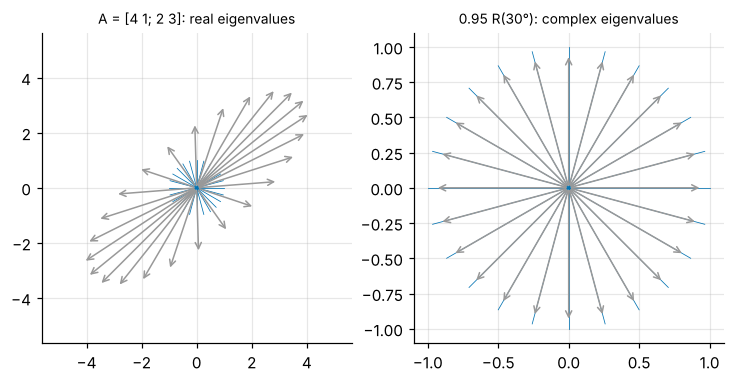

eigenvalues of 0.95 R(30 deg): [0.8227+0.475j 0.8227-0.475j]  |lambda| = [0.95 0.95]


In [3]:
def arrows(A, ax, title):
    for t in np.linspace(0, 2 * np.pi, 24, endpoint=False):
        x = np.array([np.cos(t), np.sin(t)]); y = A @ x
        ax.annotate("", xy=y, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="0.6"))
        ax.plot([0, x[0]], [0, x[1]], color="C0", lw=0.5)
    ax.set_aspect("equal"); lim = 1.1 * max(1, np.linalg.norm(A, 2)); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_title(title, fontsize=9)

th = math.radians(30)
R = 0.95 * np.array([[math.cos(th), -math.sin(th)], [math.sin(th), math.cos(th)]])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
arrows(A, axes[0], "A = [4 1; 2 3]: real eigenvalues")
arrows(R, axes[1], "0.95 R(30°): complex eigenvalues")
plt.show()
print("eigenvalues of 0.95 R(30 deg):", np.linalg.eigvals(R), " |lambda| =", abs(np.linalg.eigvals(R)))

## Part 2 — The wearable's power states as a Markov chain

Example 02-08.2, column convention: $\mathbf{u}_{k+1} = \mathbf{P}\mathbf{u}_k$ with states (Active, Idle, Sleep).

**🔮 Predict:** starting from "always active", after how many 1 ms steps is every state's probability within 0.01 of its steady-state value?

eigenvalues: [1.     0.9338 0.7462]
steady state (A, I, S): [0.1786 0.1071 0.7143]   average current: 0.9479 mA
first step with every component within 0.01 of steady state: 66


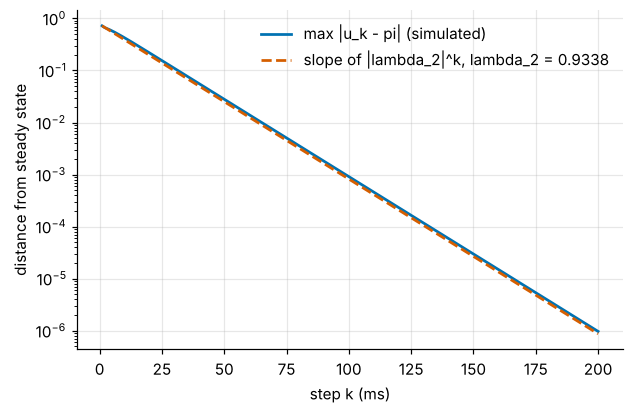

In [4]:
P = np.array([[0.90, 0.10, 0.01],
              [0.08, 0.80, 0.01],
              [0.02, 0.10, 0.98]])
I_state = np.array([5.0, 0.5, 0.002])          # mA in Active, Idle, Sleep
lam, X = np.linalg.eig(P)
k1 = np.argmin(abs(lam - 1))
pi = np.real(X[:, k1]); pi = pi / pi.sum()
print("eigenvalues:", np.sort(np.real(lam))[::-1])
print("steady state (A, I, S):", pi, "  average current:", round(I_state @ pi, 4), "mA")

u = np.array([1.0, 0.0, 0.0]); errs = []; first = None
for k in range(1, 201):
    u = P @ u
    errs.append(np.max(np.abs(u - pi)))
    if first is None and errs[-1] < 0.01:
        first = k
print("first step with every component within 0.01 of steady state:", first)
lam2 = np.sort(np.abs(lam))[-2]
plt.semilogy(range(1, 201), errs, label="max |u_k - pi| (simulated)")
plt.semilogy(range(1, 201), errs[0] / lam2 * lam2 ** np.arange(1, 201), "--", label=f"slope of |lambda_2|^k, lambda_2 = {lam2:.4f}")
plt.xlabel("step k (ms)"); plt.ylabel("distance from steady state"); plt.legend(); plt.show()

The power method: repeated multiplication finds the dominant eigenvector (here, the steady state) without solving anything.

In [5]:
v = np.ones(3) / 3
for it in range(1, 1000):
    v_new = P @ v; v_new /= v_new.sum()
    if np.max(np.abs(v_new - v)) < 1e-12:
        break
    v = v_new
print(f"power method after {it} iterations: {v_new}  (eigenvector: {pi})")

power method after 349 iterations: [0.1786 0.1071 0.7143]  (eigenvector: [0.1786 0.1071 0.7143])


## Part 3 — Spirals and poles

**🔮 Predict:** the digital resonator $r\,\mathbf{R}_{30°}$ with $r = 1.02$ instead of 0.95. What happens to the amplitude after one 12-step oscillation?

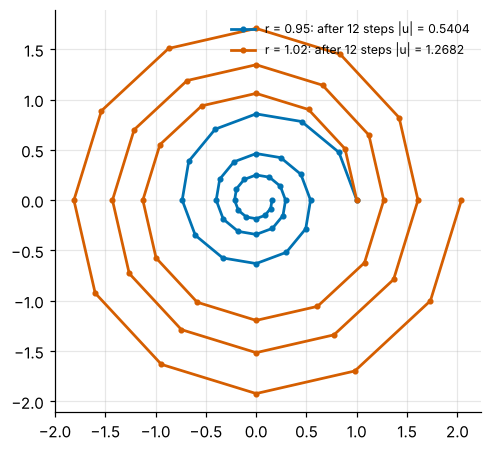

RLC companion-matrix eigenvalues: [-2500.+9682.4584j -2500.-9682.4584j]


In [6]:
fig, ax = plt.subplots(figsize=(5, 5))
for r, col in ((0.95, "C0"), (1.02, "C1")):
    M = r * np.array([[math.cos(th), -math.sin(th)], [math.sin(th), math.cos(th)]])
    u = np.array([1.0, 0.0]); pts = [u]
    for _ in range(36):
        u = M @ u; pts.append(u)
    pts = np.array(pts)
    ax.plot(pts[:, 0], pts[:, 1], "o-", color=col, ms=3, label=f"r = {r}: after 12 steps |u| = {np.linalg.norm(pts[12]):.4f}")
ax.set_aspect("equal"); ax.legend(fontsize=8); plt.show()

alpha, w0sq = 2500.0, 1e8
print("RLC companion-matrix eigenvalues:", np.linalg.eigvals(np.array([[0, 1], [-w0sq, -2 * alpha]])))

## Part 4 — Modes of a ladder

**🔮 Predict:** for a 20-node ladder (the 20×20 version of $\mathbf{K}$), what will the eigenvectors with the smallest and largest eigenvalues look like?

smallest and largest eigenvalues: 0.02233834754974213 3.9776616524502564
formula 2 - 2cos(k pi/(n+1)):       0.022338347549742954 3.977661652450257
Q^T Q = I: True    positive definite: True


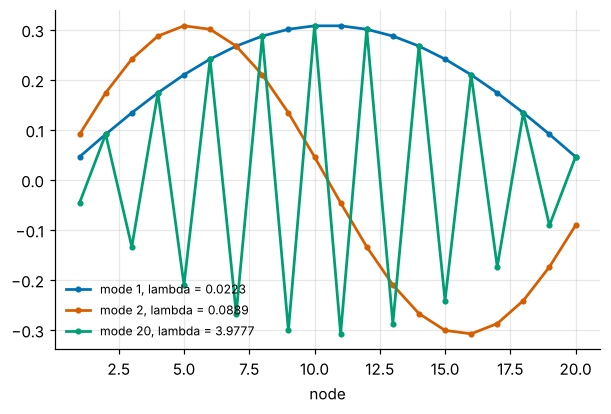

In [7]:
n = 20
K = 2 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1)
w, Q = np.linalg.eigh(K)                    # symmetric solver: real eigenvalues, orthonormal Q
print("smallest and largest eigenvalues:", w[0], w[-1])
print("formula 2 - 2cos(k pi/(n+1)):      ", 2 - 2 * math.cos(math.pi / (n + 1)), 2 - 2 * math.cos(n * math.pi / (n + 1)))
print("Q^T Q = I:", np.allclose(Q.T @ Q, np.eye(n)), "   positive definite:", np.all(w > 0))
for idx in (0, 1, n - 1):
    plt.plot(range(1, n + 1), Q[:, idx], "o-", ms=3, label=f"mode {idx + 1}, lambda = {w[idx]:.4f}")
plt.xlabel("node"); plt.legend(fontsize=8); plt.show()

## Part 5 — Coupled resonators

Mode frequencies versus coupling, and the beat when only resonator 1 starts ringing (Example 02-08.5).

Cc = 0.00 nF: mode frequencies [5.0329 5.0329] MHz, eigenvectors (columns)
[[1. 0.]
 [0. 1.]]
Cc = 0.05 nF: mode frequencies [5.0329 4.7987] MHz, eigenvectors (columns)
[[-0.7071 -0.7071]
 [-0.7071  0.7071]]
Cc = 0.10 nF: mode frequencies [5.0329 4.5944] MHz, eigenvectors (columns)
[[-0.7071 -0.7071]
 [-0.7071  0.7071]]
Cc = 0.20 nF: mode frequencies [5.0329 4.2536] MHz, eigenvectors (columns)
[[-0.7071 -0.7071]
 [-0.7071  0.7071]]


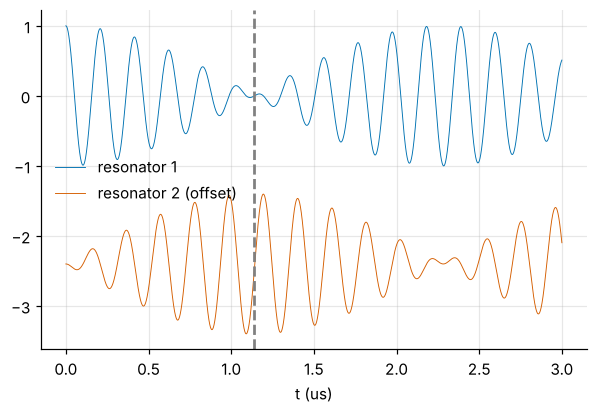

complete transfer at 1.1402 us


In [8]:
L, C = 1e-6, 1e-9
for Cc in (0.0, 0.05e-9, 0.1e-9, 0.2e-9):
    Cm = np.array([[C + Cc, -Cc], [-Cc, C + Cc]])
    caps, modes = np.linalg.eigh(Cm)
    f = 1 / (2 * np.pi * np.sqrt(L * caps))
    print(f"Cc = {Cc*1e9:4.2f} nF: mode frequencies {np.sort(f)[::-1] / 1e6} MHz, eigenvectors (columns)\n{modes}")

w1, w2 = 1 / math.sqrt(L * C), 1 / math.sqrt(L * 1.2e-9)
t = np.linspace(0, 3e-6, 6000)
plt.plot(t * 1e6, 0.5 * (np.cos(w1 * t) + np.cos(w2 * t)), lw=0.6, label="resonator 1")
plt.plot(t * 1e6, 0.5 * (np.cos(w1 * t) - np.cos(w2 * t)) - 2.4, lw=0.6, label="resonator 2 (offset)")
plt.axvline(math.pi / (w1 - w2) * 1e6, ls="--", color="0.5")
plt.xlabel("t (us)"); plt.legend(); plt.show()
print(f"complete transfer at {math.pi / (w1 - w2) * 1e6:.4f} us")

## Part 6 — The SVD and low-rank approximation

A smooth 60×80 "image" built from three separable patterns has rank exactly 3. Add a little noise and look at its singular values.

**🔮 Predict:** how many singular values stand clearly above the noise floor?

rank of the noise-free image: 3
k = 1: 2-norm error 10.12300  vs  sigma_(k+1) = 10.12300   energy captured 91.079%
k = 2: 2-norm error 1.98012  vs  sigma_(k+1) = 1.98012   energy captured 99.636%
k = 3: 2-norm error 0.15714  vs  sigma_(k+1) = 0.15714   energy captured 99.964%
k = 5: 2-norm error 0.14877  vs  sigma_(k+1) = 0.14877   energy captured 99.968%


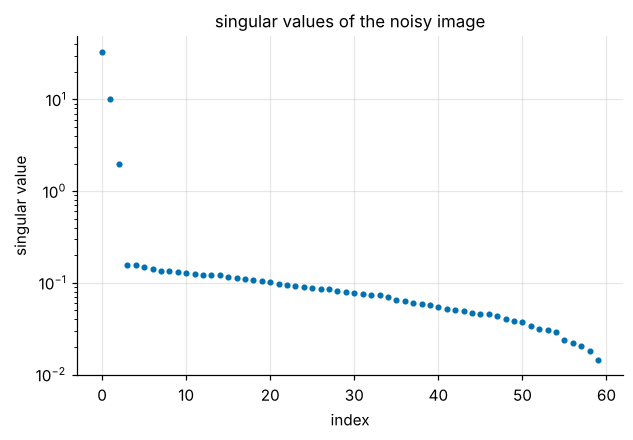

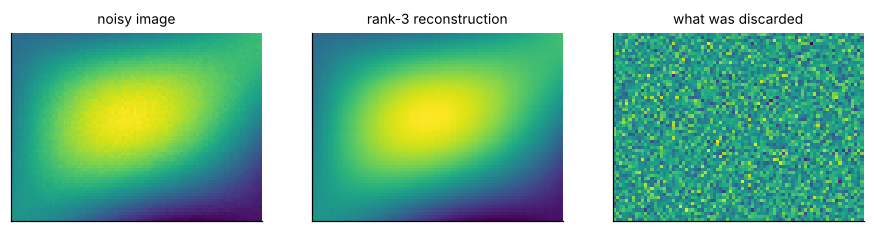

In [9]:
rng = np.random.default_rng(0)
x = np.linspace(0, 1, 80); y = np.linspace(0, 1, 60)
img = (np.outer(np.sin(np.pi * y), np.sin(np.pi * x))
       + 0.5 * np.outer(np.cos(3 * y), x**2)
       + 0.25 * np.outer(y, np.cos(5 * x)))
print("rank of the noise-free image:", np.linalg.matrix_rank(img))
noisy = img + 0.01 * rng.standard_normal(img.shape)
U, s, Vt = np.linalg.svd(noisy, full_matrices=False)
for k in (1, 2, 3, 5):
    Ak = (U[:, :k] * s[:k]) @ Vt[:k]
    print(f"k = {k}: 2-norm error {np.linalg.norm(noisy - Ak, 2):.5f}  vs  sigma_(k+1) = {s[k]:.5f}   "
          f"energy captured {100 * (s[:k]**2).sum() / (s**2).sum():.3f}%")
plt.semilogy(s, "o", ms=3); plt.xlabel("index"); plt.ylabel("singular value"); plt.title("singular values of the noisy image"); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, M, title in ((axes[0], noisy, "noisy image"), (axes[1], (U[:, :3] * s[:3]) @ Vt[:3], "rank-3 reconstruction"),
                     (axes[2], noisy - (U[:, :3] * s[:3]) @ Vt[:3], "what was discarded")):
    ax.imshow(M, cmap="viridis"); ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.show()

## Part 7 — ngspice

From the repository root, run `python tools/run_spice.py 02-08`. The netlist `coupled_lc.cir` drives each coupled pair in an eigenvector pattern: in phase $(1, 1)$ or anti-phase $(1, -1)$. Each pattern excites only its own mode, so the response peaks at exactly that mode's frequency: 5.033 and 4.594 MHz for Example 02-08.5, and 4.949 and 4.518 MHz for Problem 02-08.13.

## Your turn

1. In Part 2, halve the probability of leaving Sleep for Active (0.01 → 0.005) and rebalance the column. Predict how the average current and the convergence time change, then check.
2. In Part 6, raise the noise from 0.01 to 0.1. How many singular values now stand above the noise floor, and what does that say about choosing $k$?
3. Replace the coupling capacitor of Part 5 with mutual inductance (two inductors with coupling coefficient $k$). Which mode now stays at $f_0$, and which moves?